# Neural Network for Tabular Regression (PyTorch)

Predicts **medical insurance charges** from a person's age, sex, BMI, number of children, smoker status and region.
Dataset: Kaggle's **Medical Cost Personal Datasets** (`insurance.csv`, about 1,300 rows).

**Steps:** 1) Config, 2) Load and explore, 3) Preprocess, 4) Baseline, 5) Model, 6) Train, 7) Evaluate, 8) Save.

Before running, download the data into a `data/` folder next to this notebook:
```
kaggle datasets download -d mirichoi0218/insurance --unzip -p data/
```
After this, `data/insurance.csv` should exist. You can also download it manually from the dataset page on Kaggle.

## 1. Imports and configuration

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


In [2]:
# ---- CHANGE THESE FOR A DIFFERENT DATASET ----
DATA_PATH = "data/insurance.csv"   # path to your Kaggle CSV
TARGET = "charges"                 # the column you want to predict
ID_COLS = []                       # columns to ignore (row IDs etc.)
LOG_TARGET = True                  # True helps when the target is skewed (prices, costs)

# ---- Training settings ----
BATCH_SIZE = 32
LEARNING_RATE = 1e-3
MAX_EPOCHS = 300
PATIENCE = 25                      # stop if validation loss does not improve for this many epochs

## 2. Load and explore the data

In [3]:
df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


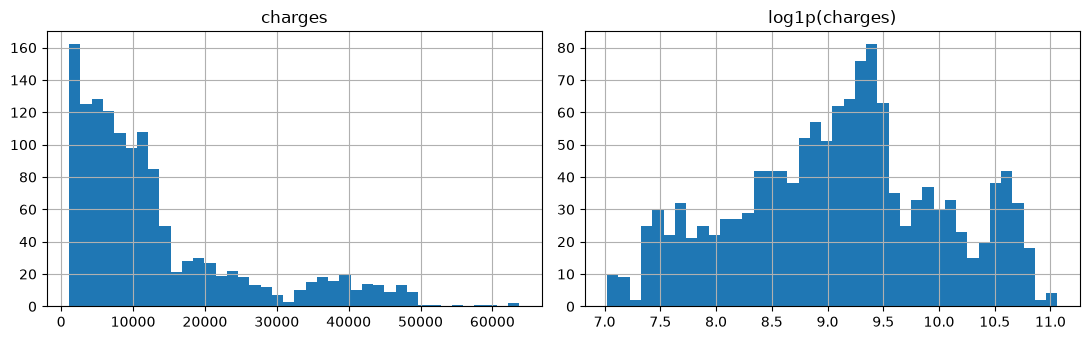

Missing values per column:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
df[TARGET].hist(bins=40, ax=ax[0]); ax[0].set_title(TARGET)
np.log1p(df[TARGET]).hist(bins=40, ax=ax[1]); ax[1].set_title(f"log1p({TARGET})")
plt.tight_layout(); plt.show()

print("Missing values per column:")
print(df.isna().sum())

In [6]:
# Smoking has a very strong effect on charges, so it is worth a look
if "smoker" in df.columns:
    df.groupby("smoker")[TARGET].describe()

## 3. Preprocess

- Drop ID columns and columns with more than 40% missing values
- One-hot encode text columns (sex, smoker, region)
- Split 70/15/15 into train, validation and test
- Fill missing numbers with the **training** median, then scale using the **training** set only, so no test information leaks in

In [7]:
df = df.drop(columns=ID_COLS, errors="ignore").dropna(subset=[TARGET])

y = df[TARGET].astype(float).values
X = df.drop(columns=[TARGET])

# drop columns that are mostly empty
too_empty = X.columns[X.isna().mean() > 0.4]
X = X.drop(columns=too_empty)
print("Dropped mostly-empty columns:", list(too_empty))

# one-hot encode text columns
cat_cols = X.select_dtypes(exclude="number").columns
X[cat_cols] = X[cat_cols].fillna("Missing")
X = pd.get_dummies(X, columns=list(cat_cols), dtype=float)
print("Feature count after encoding:", X.shape[1])

# split: 70% train, 15% validation, 15% test
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.30, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, random_state=SEED)

# fill missing numbers using training medians only
medians = X_train.median()
X_train = X_train.fillna(medians)
X_val = X_val.fillna(medians)
X_test = X_test.fillna(medians)

# scale features (fit on train only)
x_scaler = StandardScaler().fit(X_train)
Xtr, Xva, Xte = (x_scaler.transform(a) for a in (X_train, X_val, X_test))

# transform and scale the target (fit on train only)
def prep_target(v):
    return np.log1p(v) if LOG_TARGET else v

y_scaler = StandardScaler().fit(prep_target(y_train).reshape(-1, 1))
ytr, yva, yte = (y_scaler.transform(prep_target(a).reshape(-1, 1)) for a in (y_train, y_val, y_test))

def to_original(pred_scaled):
    out = y_scaler.inverse_transform(np.asarray(pred_scaled).reshape(-1, 1)).ravel()
    return np.expm1(out) if LOG_TARGET else out

print("Train / val / test sizes:", len(Xtr), len(Xva), len(Xte))

Dropped mostly-empty columns: []
Feature count after encoding: 11
Train / val / test sizes: 936 201 201


In [8]:
def make_loader(X_, y_, shuffle):
    ds = TensorDataset(torch.tensor(X_, dtype=torch.float32), torch.tensor(y_, dtype=torch.float32))
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle)

train_loader = make_loader(Xtr, ytr, True)
val_loader = make_loader(Xva, yva, False)
test_loader = make_loader(Xte, yte, False)

## 4. Baseline: linear regression
The neural network should at least match this. If it does not, something needs tuning.

In [9]:
def report(name, y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"{name:<22} RMSE: {rmse:>12,.2f}   MAE: {mae:>12,.2f}   R2: {r2:.4f}")
    return rmse, mae, r2

lin = LinearRegression().fit(Xtr, ytr)
_ = report("Linear regression", y_test, to_original(lin.predict(Xte)))

Linear regression      RMSE:     7,793.21   MAE:     3,957.03   R2: 0.5995


## 5. Define the neural network

In [10]:
class RegressionNet(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, 64), nn.ReLU(), nn.Dropout(0.1),
            nn.Linear(64, 32), nn.ReLU(), nn.Dropout(0.1),
            nn.Linear(32, 1),
        )

    def forward(self, x):
        return self.net(x)

model = RegressionNet(Xtr.shape[1]).to(device)
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
print(model)

RegressionNet(
  (net): Sequential(
    (0): Linear(in_features=11, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.1, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)


## 6. Train
Keeps the weights with the best validation loss and stops early when it stops improving.

In [11]:
def run_epoch(loader, train):
    model.train(train)
    total = 0.0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            loss = loss_fn(model(xb), yb)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total += loss.item() * len(xb)
    return total / len(loader.dataset)

history = {"train": [], "val": []}
best_val, best_state, wait = float("inf"), None, 0

for epoch in range(1, MAX_EPOCHS + 1):
    tr = run_epoch(train_loader, True)
    va = run_epoch(val_loader, False)
    history["train"].append(tr)
    history["val"].append(va)

    if va < best_val:
        best_val, wait = va, 0
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    else:
        wait += 1

    if epoch % 10 == 0 or epoch == 1:
        print(f"Epoch {epoch:>3}  train loss {tr:.4f}  val loss {va:.4f}")
    if wait >= PATIENCE:
        print(f"Early stopping at epoch {epoch}")
        break

model.load_state_dict(best_state)
print("Best validation loss:", round(best_val, 4))

Epoch   1  train loss 0.8171  val loss 0.5675
Epoch  10  train loss 0.1878  val loss 0.1599
Epoch  20  train loss 0.1747  val loss 0.1644
Epoch  30  train loss 0.1702  val loss 0.1623
Epoch  40  train loss 0.1663  val loss 0.1604
Early stopping at epoch 40
Best validation loss: 0.1591


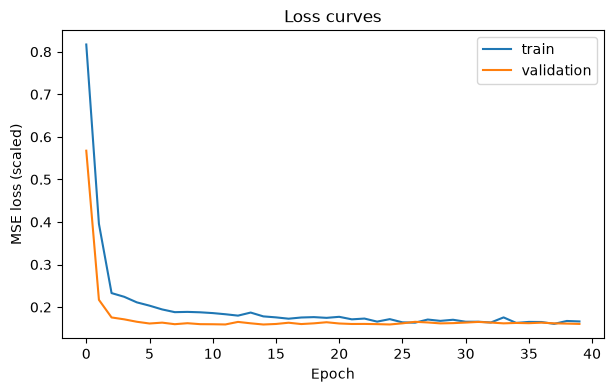

In [12]:
plt.figure(figsize=(7, 4))
plt.plot(history["train"], label="train")
plt.plot(history["val"], label="validation")
plt.xlabel("Epoch"); plt.ylabel("MSE loss (scaled)"); plt.legend(); plt.title("Loss curves")
plt.show()

## 7. Evaluate on the test set
The test set has not been used for training or for choosing the best epoch.

In [13]:
model.eval()
with torch.no_grad():
    pred_scaled = model(torch.tensor(Xte, dtype=torch.float32).to(device)).cpu().numpy()
pred = to_original(pred_scaled)

report("Linear regression", y_test, to_original(lin.predict(Xte)))
report("Neural network", y_test, pred)

Linear regression      RMSE:     7,793.21   MAE:     3,957.03   R2: 0.5995
Neural network         RMSE:     4,591.89   MAE:     2,336.37   R2: 0.8610


(np.float64(4591.893819739817), 2336.3700161283427, 0.8609587650695469)

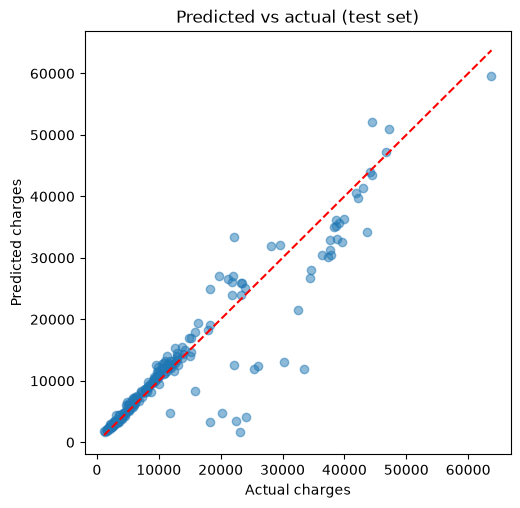

In [14]:
plt.figure(figsize=(5.5, 5.5))
plt.scatter(y_test, pred, alpha=0.5)
lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
plt.plot(lims, lims, "r--")
plt.xlabel("Actual charges"); plt.ylabel("Predicted charges"); plt.title("Predicted vs actual (test set)")
plt.show()

## 8. Save the model
Saves the weights plus everything needed to reuse the model later.

In [15]:
os.makedirs("models", exist_ok=True)
torch.save(model.state_dict(), "models/model.pt")
joblib.dump({
    "x_scaler": x_scaler,
    "y_scaler": y_scaler,
    "columns": list(X.columns),
    "medians": medians,
    "log_target": LOG_TARGET,
}, "models/preprocessing.joblib")
print("Saved to models/")

Saved to models/


## Next steps

- Tune `LEARNING_RATE`, layer sizes, dropout and `BATCH_SIZE`
- Try feature engineering (for example BMI categories, or smoker x BMI interaction)
- Compare with gradient boosting (XGBoost / LightGBM), which often wins on tabular data
- Commit this notebook to GitHub (see the README)